# How to use the OpenAI Image API

This notebook uses OpenAI's Images API to generate, edit, and save images.

The Images API supports:
- **Generations:** creates images from a text prompt
- **Edits:** modifies an existing image using a prompt and mask

The variations section demonstrates generating multiple images from a prompt.

### See for more details:

https://openai.com/index/dall-e/

## Setup

- Import the packages you'll need
- Import your OpenAI API key: You can do this by running \``export OPENAI_API_KEY="your API key"`\` in your terminal.
- Set a directory to save images to

In [9]:
!pip install openai

In [10]:
import os
import openai

from dotenv import load_dotenv
load_dotenv()


OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")




In [11]:
# imports
from openai import OpenAI  # OpenAI Python library to make API calls
import base64  # used to decode generated image data
import os  # used to access filepaths
from PIL import Image  # used to print and edit images




In [12]:

# initialize OpenAI client
client = OpenAI(api_key=os.environ.get("OPENAI_API_KEY", OPENAI_API_KEY))

In [13]:
# set a directory to save generated images to
image_dir_name = "images"
image_dir = os.path.join(os.curdir, image_dir_name)

# create the directory if it doesn't yet exist
if not os.path.isdir(image_dir):
    os.mkdir(image_dir)

# print the directory to save to
print(f"{image_dir=}")


image_dir='./images'


## Generations

The generation API endpoint creates an image based on a text prompt. [API Reference](https://platform.openai.com/docs/api-reference/images/create)

**Required inputs:**
- `prompt` (str): A text description of the desired image(s).

**Optional inputs:**
- `model` (str): The image model to use, such as `gpt-image-2.5-sunburst`.
- `n` (int): The number of images to generate; defaults to 1.
- `quality` (str): Controls the generated image quality.
- `size` (str): The requested output dimensions.

The response contains the image as base64 data in `b64_json`.

In [14]:
# create an image

# set the prompt
prompt = "A cyberpunk monkey hacker dreaming of a beautiful bunch of bananas, digital art"

# call the OpenAI API
generation_response = client.images.generate(
    model = "gpt-image-2.5-sunburst",
    prompt=prompt,
    n=1,
    size="1024x1024",
)

# print response
print(generation_response)

ImagesResponse(created=1794782313, background='opaque', data=[Image(b64_json='iVBORw0KGgoAAAANSUhEUgAABAAAAAQACAIAAADwf7zUAABcYmNhQlgAAFxianVtYgAAAB5qdW1kYzJwYQ… [base64 image data truncated]


In [15]:
# save the image
generated_image_name = "generated_image.png"  # any name you like; the filetype should be .png
generated_image_filepath = os.path.join(image_dir, generated_image_name)
generated_image = base64.b64decode(generation_response.data[0].b64_json)

with open(generated_image_filepath, "wb") as image_file:
    image_file.write(generated_image)  # write the image to the file

./images/generated_image.png


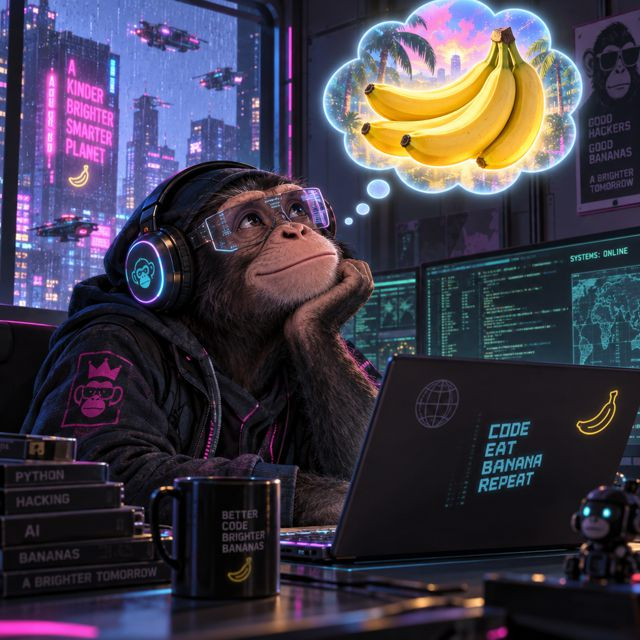

In [16]:
# print the image
print(generated_image_filepath)
display(Image.open(generated_image_filepath))


## Variations

This example simulates variations by generating new images with the same prompt. It does not use a separate variations endpoint.

The code below creates two new images from the same prompt.

In [17]:
import time

# Simulate variations by generating new images with the same prompt.
# (client.images.create_variation was removed from the OpenAI API)
NUM_VARIATIONS = 2
variation_images = []
variation_image_names = [f"variation_image_{i}.png" for i in range(NUM_VARIATIONS)]
variation_image_filepaths = [os.path.join(image_dir, name) for name in variation_image_names]

for i in range(NUM_VARIATIONS):
    for attempt in range(1, 4):
        try:
            resp = client.images.generate(
                model="gpt-image-2.5-sunburst",
                prompt=prompt,
                n=1,
                size="1024x1024",
            )
            img_bytes = base64.b64decode(resp.data[0].b64_json)
            variation_images.append(img_bytes)
            print(f"Variation {i + 1}/{NUM_VARIATIONS} generated.")
            break
        except Exception as e:
            print(f"Attempt {attempt}/3 failed: {e}")
            if attempt < 3:
                time.sleep(2 ** attempt)
            else:
                raise

print(f"{len(variation_images)} variations ready.")


Variation 1/2 generated.
Variation 2/2 generated.
2 variations ready.


In [18]:
# save the variation images to disk
for image, filepath in zip(variation_images, variation_image_filepaths):
    with open(filepath, "wb") as image_file:
        image_file.write(image)

print("Variations saved:")
for fp in variation_image_filepaths:
    print(" ", fp)


Variations saved:
  ./images/variation_image_0.png
  ./images/variation_image_1.png


./images/generated_image.png


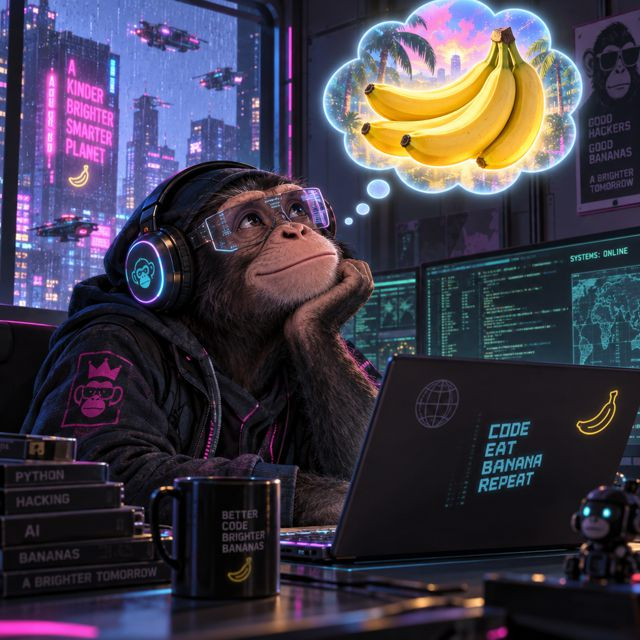

./images/variation_image_0.png


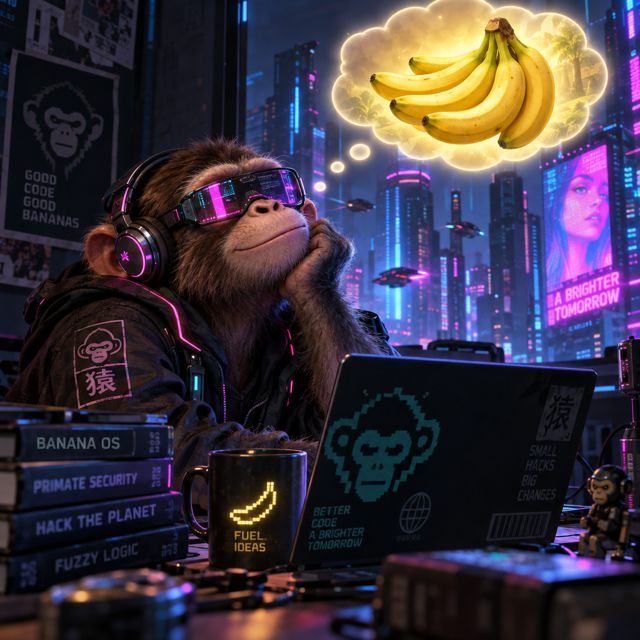

./images/variation_image_1.png


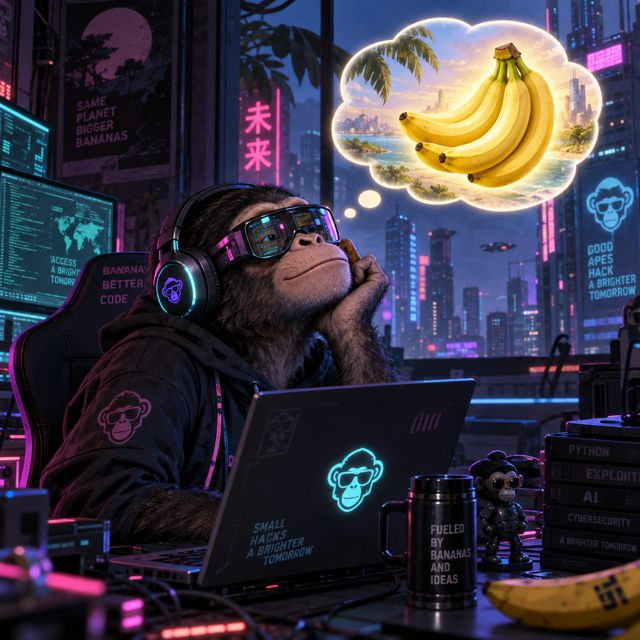

In [19]:
# print the original image
print(generated_image_filepath)
display(Image.open(generated_image_filepath))

# print the new variations
for variation_image_filepaths in variation_image_filepaths:
    print(variation_image_filepaths)
    display(Image.open(variation_image_filepaths))


## Edits

The edit endpoint modifies an existing image using a prompt and optional mask. [API Reference](https://platform.openai.com/docs/api-reference/images/createEdit)

**Required inputs:** 
- `image` (file): The image to edit.
- `prompt` (str): A text description of the desired edit.

**Optional inputs:**
- `mask` (file): An optional mask that identifies image areas to edit; transparent regions are editable.
- `model` (str): The image model to use, such as `gpt-image-2.5-sunburst`.

The response contains the edited image as base64 data in `b64_json`.


### Set Edit Area

An edit requires a "mask" to specify which portion of the image to regenerate. Any pixel with an alpha of 0 (transparent) will be regenerated. The code below creates a 1024x1024 mask where the bottom half is transparent.

In [20]:
# create a mask
width = 1024
height = 1024
mask = Image.new("RGBA", (width, height), (0, 0, 0, 1))  # create an opaque image mask

# set the bottom half to be transparent
for x in range(width):
    for y in range(height // 2, height):  # only loop over the bottom half of the mask
        # set alpha (A) to zero to turn pixel transparent
        alpha = 0
        mask.putpixel((x, y), (0, 0, 0, alpha))

# save the mask
mask_name = "bottom_half_mask.png"
mask_filepath = os.path.join(image_dir, mask_name)
mask.save(mask_filepath)

### Perform Edit

Now we supply our image, caption and mask to the API to get 5 examples of edits to our image

In [21]:
# edit an image

# call the OpenAI API
edit_response = client.images.edit(
    image=open(generated_image_filepath, "rb"),  # from the generation section
    mask=open(mask_filepath, "rb"),  # from right above
    prompt=prompt,  # from the generation section
    model="gpt-image-2.5-sunburst",
    n=1,
    size="1024x1024",
)

# print response
print(edit_response)

ImagesResponse(created=1794782414, background='opaque', data=[Image(b64_json='iVBORw0KGgoAAAANSUhEUgAABAAAAAQACAIAAADwf7zUAABVdWNhQlgAAFV1anVtYgAAAB5qdW1kYzJwYQ… [base64 image data truncated]


In [22]:
# save the image
edited_image_name = "edited_image.png"  # any name you like; the filetype should be .png
edited_image_filepath = os.path.join(image_dir, edited_image_name)
edited_image = base64.b64decode(edit_response.data[0].b64_json)

with open(edited_image_filepath, "wb") as image_file:
    image_file.write(edited_image)  # write the image to the file

./images/generated_image.png


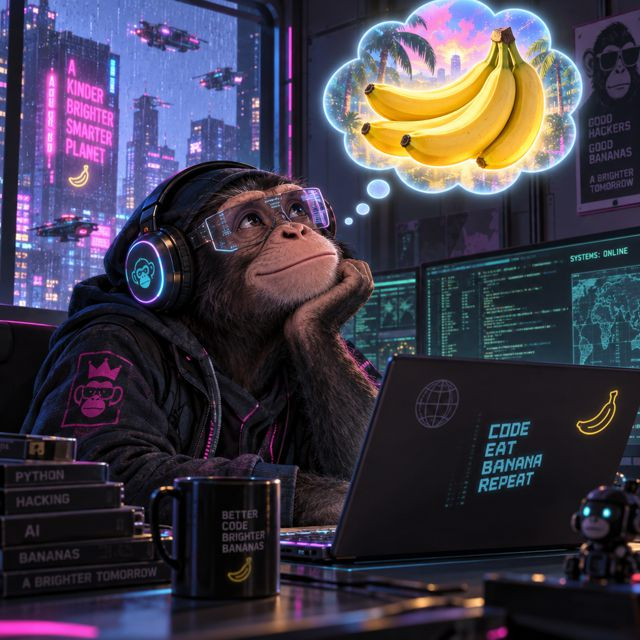

./images/edited_image.png


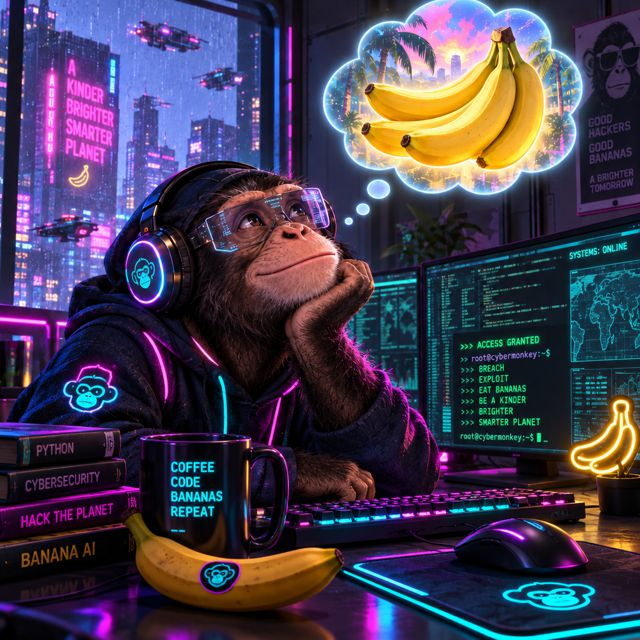

In [23]:
# print the original image
print(generated_image_filepath)
display(Image.open(generated_image_filepath))

# print edited image
print(edited_image_filepath)
display(Image.open(edited_image_filepath))